# Why the climate data does not help

Every death comes with four weather columns, and the organisers attached 13 rainfall, temperature and vegetation variables from CHIRPS, ERA5-Land and MODIS, plus elevation and slope from SRTM. This notebook measures what they add to a model that only knows the age, sex and date of death, and traces the result to the structure of the data.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from climate_health.analysis import mixed_label_groups, residual_test, share_between_dates, site_heterogeneity
from climate_health.data import CLIMATE, DEMOGRAPHIC, LOCATION, TARGET, TERRAIN, WEATHER, load
from climate_health.models import AGE_GROUPS, age_period, boosting
from climate_health.plots import BLUE, GREY, ORANGE
from climate_health.validation import compare, cross_val_predict, summarize

train, test = load()
y, sites = train[TARGET].values, train.site.values
records = pd.concat([train, test])

## 1. The climate variables follow the calendar

For each variable, the share of its variance explained by the date of death alone, over all 4,176 records. A share of 1 means that every death on a given day has the same value, wherever it happened.

Share explained by the calendar month alone: {'rain_sum_30d': 0.73, 'tavg_30d': 0.63, 'ndvi_30d': 0.35}


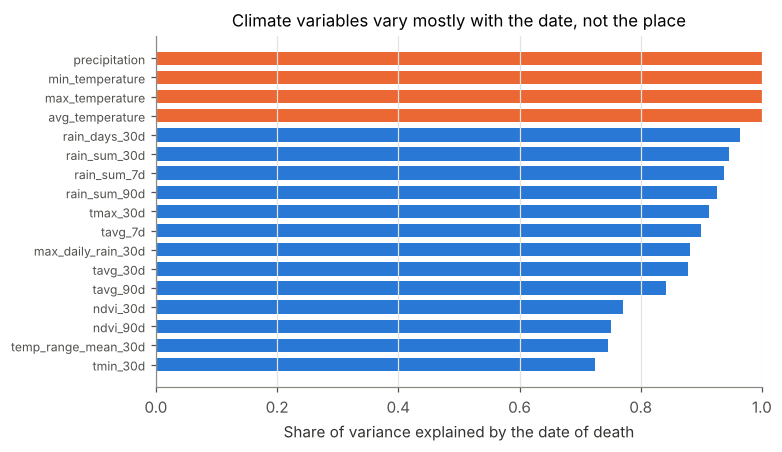

tmin_30d               0.72
temp_range_mean_30d    0.75
ndvi_90d               0.75
ndvi_30d               0.77
tavg_90d               0.84
tavg_30d               0.88
max_daily_rain_30d     0.88
tavg_7d                0.90
tmax_30d               0.91
rain_sum_90d           0.93
rain_sum_7d            0.94
rain_sum_30d           0.95
rain_days_30d          0.96
avg_temperature        1.00
max_temperature        1.00
min_temperature        1.00
precipitation          1.00
dtype: float64

In [2]:
between = pd.Series({c: share_between_dates(records, c) for c in CLIMATE + WEATHER}).sort_values()
month = records.deathdate.dt.to_period("M")
by_month = {c: 1 - records.groupby(month)[c].transform(lambda v: v - v.mean()).var() / records[c].var()
            for c in ["rain_sum_30d", "tavg_30d", "ndvi_30d"]}
print("Share explained by the calendar month alone:", {c: round(float(v), 2) for c, v in by_month.items()})

fig, ax = plt.subplots(figsize=(7, 4))
colors = [ORANGE if c in WEATHER else BLUE for c in between.index]
ax.barh(between.index, between.values, color=colors, height=0.7)
ax.set_xlim(0, 1)
ax.set_xlabel("Share of variance explained by the date of death")
ax.set_title("Climate variables vary mostly with the date, not the place")
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="y", visible=False)
fig.savefig("images/climate_by_date.png")
plt.show()
between.round(2)

Between 72% and 96% of the variance of each climate variable is shared by all deaths on the same date, and the four weather columns depend on the date alone. The calendar month by itself explains 73% of the variance of 30-day rainfall. Within the area where most deaths occur, rainfall and temperature differ little from one village to the next, so these variables mostly record when a death happened, which the model already knows from the date. The vegetation index and minimum temperature vary most between places, but differences between places are exactly what the test set cannot reward, since its sites are new.

## 2. Deaths on the same day share the weather but not the label

Groups of two or more training deaths on the same date, and on the same date at the same site.

In [3]:
pd.DataFrame({"same date": mixed_label_groups(train, "deathdate", TARGET),
              "same date and site": mixed_label_groups(train, ["site", "deathdate"], TARGET)})

,same date,same date and site
groups,673,55
mixed groups,328,23
records in mixed groups,830,46


On 328 of the 673 dates with two or more training deaths, some deaths are climate-sensitive and others are not, 830 deaths in all. These deaths share the same four weather values, and at the same site every climate variable is identical: 23 of the 55 site-days with several deaths hold both labels. A variable computed from the date and place of death takes one value for all of them, so it cannot tell them apart; what separates them is who died. Climate can only move the probability of all the deaths on the same day and place together, and the next sections show that in this data the move is too small to measure.

## 3. Adding the climate variables to a model

Two model families, both given age, sex and the date of death as years since 2007:

- **Boosting**: shallow, heavily regularised gradient-boosted trees, which can use any variable in any interaction.
- **Age-period**: a penalised logistic regression with smooth age and time effects, a time trend and a 2018 step for each age group, and sex by age group. Extra variables enter linearly.

Each feature set is scored with the challenge metric, 0.6 F1 at the 0.5 cut plus 0.4 ROC-AUC, in 5-fold cross-validation that holds out whole sites, as the test set does, repeated 10 times. Every comparison uses the same folds, and its 95% interval resamples whole sites.

In [4]:
feature_sets = {
    "Age, sex, date": DEMOGRAPHIC,
    "+ climate": DEMOGRAPHIC + CLIMATE,
    "+ weather columns": DEMOGRAPHIC + WEATHER,
    "+ place": DEMOGRAPHIC + LOCATION + TERRAIN + ["rural"],
    "+ all of these": DEMOGRAPHIC + CLIMATE + WEATHER + LOCATION + TERRAIN + ["rural"],
}
models = {"Boosting": boosting, "Age-period": age_period}

predictions, rows = {}, []
for model_name, make_model in models.items():
    for set_name, columns in feature_sets.items():
        predictions[model_name, set_name] = cross_val_predict(make_model, train[columns], y, sites)
        result = summarize(predictions[model_name, set_name], y).loc["mean"]
        if set_name != "Age, sex, date":
            result = pd.concat([result, pd.Series(compare(
                predictions[model_name, "Age, sex, date"], predictions[model_name, set_name], y, sites))])
        rows.append(result.rename((model_name, set_name)))
ablation = pd.DataFrame(rows)
ablation.round(4)

score      F1     AUC  difference     low  \
Boosting   Age, sex, date     0.8163  0.8116  0.8234         NaN     NaN   
           + climate          0.8056  0.8017  0.8114     -0.0108 -0.0147   
           + weather columns  0.8077  0.8048  0.8120     -0.0086 -0.0136   
           + place            0.8131  0.8093  0.8187     -0.0033 -0.0064   
           + all of these     0.8040  0.8007  0.8091     -0.0123 -0.0174   
Age-period Age, sex, date     0.8192  0.8150  0.8254         NaN     NaN   
           + climate          0.8165  0.8132  0.8214     -0.0027 -0.0055   
           + weather columns  0.8178  0.8135  0.8242     -0.0014 -0.0025   
           + place            0.8051  0.8039  0.8069     -0.0141 -0.0361   
           + all of these     0.7915  0.7926  0.7899     -0.0277 -0.0804   

                                high  P(better)  
Boosting   Age, sex, date        NaN        NaN  
           + climate         -0.0007     0.0185  
           + weather columns -0.0042     0.0000  
           + place           -0.0001     0.0190  
           + all of these    -0.0041     0.0000  
Age-period Age, sex, date        NaN        NaN  
           + climate          0.0022     0.1860  
           + weather columns  0.0005     0.0920  
           + place           -0.0001     0.0225  
           + all of these    -0.0005     0.0130

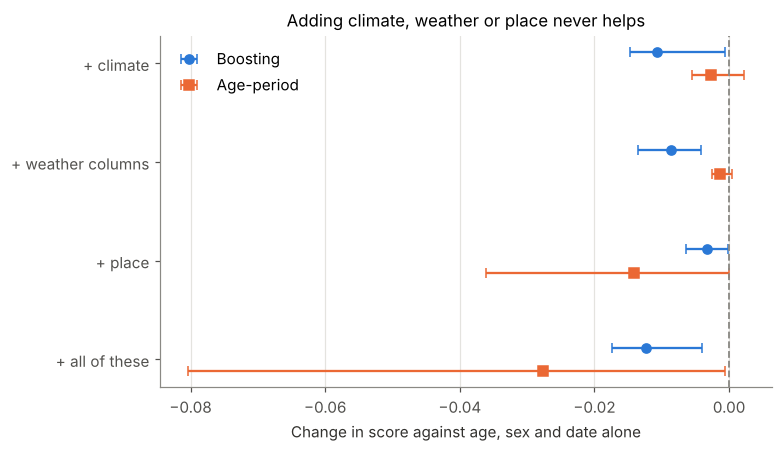

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
added = [name for name in feature_sets if name != "Age, sex, date"]
for offset, (model_name, color, marker) in zip([-0.12, 0.12], [("Boosting", BLUE, "o"), ("Age-period", ORANGE, "s")]):
    part = ablation.loc[model_name].loc[added]
    positions = np.arange(len(added)) + offset
    ax.errorbar(part["difference"], positions, xerr=[part["difference"] - part["low"], part["high"] - part["difference"]],
                fmt=marker, color=color, ecolor=color, elinewidth=1.5, capsize=3, markersize=6, label=model_name)
ax.axvline(0, color=GREY, linestyle="--", linewidth=1.2)
ax.set_yticks(range(len(added)), added)
ax.invert_yaxis()
ax.set_xlabel("Change in score against age, sex and date alone")
ax.set_title("Adding climate, weather or place never helps")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper left")
fig.savefig("images/climate_ablation.png")
plt.show()

No climate, weather or place variable improves either model. The age-period model changes by −0.003 with the climate variables and −0.001 with the weather columns, both within noise. The boosted trees lose 0.009 to 0.011, more than the noise, because the extra variables give them more ways to fit chance patterns in 3,146 deaths. Place variables do most harm when they enter linearly: latitude and longitude extrapolate to held-out sites far from the training ones, and the age-period model loses 0.014. The best score in the table, 0.8192, comes from age, sex and date alone.

## 4. Testing each variable on its own

A group of 13 variables can hide one useful variable among noisy ones, so each variable is also tested alone. The age-period model's out-of-fold predictions enter a logistic regression as a fixed offset, and a likelihood-ratio test asks whether the variable explains anything that age, sex and date have not already explained, either as one effect or as a separate effect in each of the six age groups. The season enters as the sine and cosine of the day of the year.

40 tests; smallest p = 0.030; Bonferroni threshold = 0.0013
Season: {'one effect': 0.423, 'by age group': 0.546}


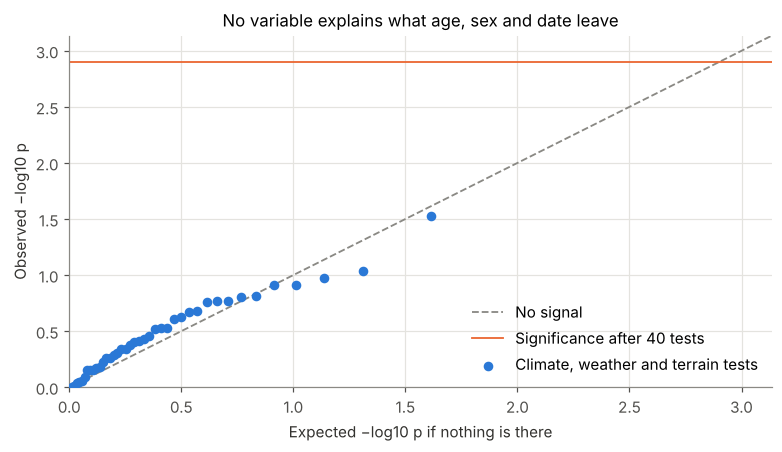

ndvi_90d            by age group    0.0296
max_daily_rain_30d  by age group    0.0924
rain_sum_30d        by age group    0.1064
ndvi_90d            one effect      0.1221
rain_sum_30d        one effect      0.1222
max_daily_rain_30d  one effect      0.1536
ndvi_30d            one effect      0.1555
precipitation       by age group    0.1695
dtype: float64

In [6]:
base_probability = predictions["Age-period", "Age, sex, date"].mean(0)
age_group = np.digitize(train.age, AGE_GROUPS)
day = 2 * np.pi * train.deathdate.dt.dayofyear / 365.25
candidates = {c: train[[c]].values for c in CLIMATE + WEATHER + TERRAIN}
candidates["season"] = np.column_stack([np.sin(day), np.cos(day)])

p_values = {}
for name, z in candidates.items():
    z = (z - z.mean(0)) / z.std(0)
    by_group = np.hstack([z * (age_group == g)[:, None] for g in range(len(AGE_GROUPS) + 1)])
    p_values[name, "one effect"] = residual_test(y, base_probability, z)
    p_values[name, "by age group"] = residual_test(y, base_probability, by_group)
p_values = pd.Series(p_values).sort_values()
print(f"{len(p_values)} tests; smallest p = {p_values.iloc[0]:.3f}; "
      f"Bonferroni threshold = {0.05 / len(p_values):.4f}")
print("Season:", p_values.loc["season"].round(3).to_dict())

fig, ax = plt.subplots(figsize=(7, 4))
expected = -np.log10(np.arange(1, len(p_values) + 1) / (len(p_values) + 1))
limit = max(expected.max(), -np.log10(0.05 / len(p_values))) * 1.08
ax.plot([0, limit], [0, limit], color=GREY, linestyle="--", linewidth=1.2, label="No signal")
ax.axhline(-np.log10(0.05 / len(p_values)), color=ORANGE, linewidth=1.2, label=f"Significance after {len(p_values)} tests")
ax.scatter(expected, -np.log10(p_values.values), color=BLUE, s=28, zorder=3, label="Climate, weather and terrain tests")
ax.set_xlim(0, limit)
ax.set_ylim(0, limit)
ax.set_xlabel("Expected −log10 p if nothing is there")
ax.set_ylabel("Observed −log10 p")
ax.set_title("No variable explains what age, sex and date leave")
ax.legend(loc="lower right")
fig.savefig("images/residual_tests.png")
plt.show()
p_values.head(8).round(4)

The 40 p-values follow the line expected when there is nothing to find. The smallest, 0.03 for the 90-day vegetation index by age group, is about what the smallest of 40 tests gives by chance, and far above the 0.0013 required after correcting for 40 tests. The season shows no effect either (p = 0.42 as one effect, 0.55 by age group).

## 5. Sites add nothing either

If some villages had more climate-sensitive deaths than their age, sex and dates imply, place variables could still help. The test compares observed and expected climate-sensitive deaths site by site, using the same out-of-fold predictions.

In [7]:
pd.Series(site_heterogeneity(y, base_probability, sites)).round(3)

sites      43.000
chi2       29.090
p           0.948
sd of z     0.830
dtype: float64

Observed and expected counts agree at every site: the chi-squared statistic is 29.1 on 43 sites (p = 0.95), and the site deviations spread less than chance alone would make them (standard deviation 0.83 against 1). Once age, sex and date are known, the place of death adds no information, so variables that describe a place, such as its elevation, slope or usual climate, can only act as site identifiers, and the test sites are new.